# 04 · Clusterização dos países

Agrupa os países pela **forma da trajetória** de indicadores demográficos entre 1950 e 2023, com DTW (*Dynamic Time Warping*) e k-means.

O notebook faz quatro coisas:

1. **Grade de parâmetros:** testa conjuntos de indicadores, filtros de população e número de grupos, medindo silhueta e estabilidade entre sementes.
2. **Modelo final:** ajusta o modelo com a configuração escolhida na grade e nomeia os grupos.
3. **Mapa dos grupos:** mostra o resultado no mapa-múndi, e depois a clusterização transversal por época.
4. **Sankey:** mostra como os países migram entre grupos de 1950 a 2100.

**Saída:** `data/processed/clusters_dtw.csv`, lido pelo dashboard.

In [1]:
import sys
from pathlib import Path

# Permite importar src/ a partir da pasta notebooks/
if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

import altair as alt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from tslearn.clustering import TimeSeriesKMeans
from tslearn.metrics import cdist_dtw
from vega_datasets import data

from src.dados import carregar_medium, paises
from src.preparo import matriz_series, padronizar

alt.data_transformers.disable_max_rows()

RAIZ = Path.cwd().parent
medium = carregar_medium()
paises_medium = paises(medium)
from src.dados import carregar_suplemento
paises_medium = paises_medium.copy()
paises_medium["logPop"] = np.log10(paises_medium["TPopulation1July"])
paises_medium = paises_medium.merge(
    carregar_suplemento()[["LocID", "Time", "LE60"]], on=["LocID", "Time"], how="left")
MALHA = alt.topo_feature(data.world_110m.url, "countries")

PERIODO = (1950, 2023)
CORES = ["#2a78d6", "#1baf7a", "#eda100", "#eb6834", "#e87ba4", "#6250d6", "#008300"]

# --- Figuras: fundo branco, texto preto, salvas em figures/ ---
import re as _re
import vl_convert as vlc
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PASTA_FIG = RAIZ / "figures"
PASTA_FIG.mkdir(exist_ok=True)
PREFIXO_FIG = "04"
_renderer_padrao = alt.renderers.get()
_contador_fig = {"n": 0}

def _titulo_de(spec):
    t = spec.get("title")
    if isinstance(t, dict):
        t = t.get("text")
    if isinstance(t, list):
        t = " ".join(map(str, t))
    if isinstance(t, str) and t:
        return t
    for chave in ("layer", "hconcat", "vconcat", "concat"):
        for sub in spec.get(chave, []):
            r = _titulo_de(sub)
            if r:
                return r
    return None

def _nome_grafico(spec):
    t = _titulo_de(spec) or "chart"
    slug = _re.sub(r"[^a-zA-Z0-9]+", "_", str(t).lower()).strip("_")
    return slug[:60] or "chart"

def _renderer_com_figuras(spec, **metadata):
    _contador_fig["n"] += 1
    base = f"{PREFIXO_FIG}_{_contador_fig['n']:02d}_{_nome_grafico(spec)}"
    spec_branco = dict(spec, background="white")
    (PASTA_FIG / f"{base}.png").write_bytes(vlc.vegalite_to_png(spec_branco, scale=2))
    if '"params"' in str(spec) and '"bind"' in str(spec):
        alt.VegaLite(spec_branco).save(str(PASTA_FIG / f"{base}.html"))
    return _renderer_padrao(spec, **metadata)

alt.renderers.register("com_figuras", _renderer_com_figuras)
alt.renderers.enable("com_figuras")

EN_GRUPO = {
    "Baixa fecundidade": "Low fertility",
    "Transição avançada": "Advanced transition",
    "Transição inicial": "Early transition",
    "Transição intermediária": "Intermediate transition",
    "Alta fecundidade": "High fertility",
}


/Users/marcosabilio/.pyenv/versions/3.12.3/lib/python3.12/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


## Fundamentos

- **DTW (*Dynamic Time Warping*):** mede a distância entre duas séries temporais alinhando-as no tempo. Dois países que fizeram a mesma transição em épocas diferentes ficam próximos, porque o alinhamento corrige a defasagem. A distância é o custo do alinhamento de menor custo.
- **k-means:** divide os países em K grupos, minimizando a distância de cada país ao centro (centroide) do seu grupo. O resultado depende da inicialização, por isso rodamos várias sementes. Com DTW, o centroide é uma série média alinhada.
- **Hierárquica (ligação média):** começa com cada país isolado e junta, a cada passo, os dois grupos mais próximos. Não depende de semente e mostra a estrutura no dendrograma.
- **Silhueta:** para cada país, compara a distância ao próprio grupo com a distância ao grupo vizinho. Vai de −1 a 1; valores acima de 0,25 indicam alguma estrutura.
- **ARI (índice de Rand ajustado):** compara duas partições. 1 significa partições iguais; 0, partições aleatórias. Aqui mede estabilidade.
- **KNN (k vizinhos mais próximos):** classifica um país pelos rótulos dos vizinhos mais próximos. Não agrupa: serve para validar os grupos e para atribuir grupos a países de fora.

A teoria por trás dos grupos é a transição demográfica (notebook 01): fecundidade e mortalidade caem em sequência, e a população envelhece.

## 1. Parâmetros da grade

- **Conjuntos de indicadores:** o conjunto A é o de referência. O conjunto B acrescenta a migração líquida. A migração não faz parte da teoria da transição e varia muito entre países (notebook 01), por isso é um teste de robustez, não o padrão.
- **População mínima:** descarta países pequenos (séries ruidosas). O valor é em milhares; 1000 equivale a 1 milhão de habitantes.
- **Número de grupos (K)** e **sementes:** a estabilidade é medida pelo ARI entre duas sementes.

In [2]:
CONJUNTOS = {
    "A: TFR, LEx, IMR, idade": ["TFR", "LEx", "IMR", "MedianAgePop"],
    "B: A + migração": ["TFR", "LEx", "IMR", "MedianAgePop", "NetMigrations"],
    "C: 11 variáveis (VIF)": ["NRR", "MAC", "CDR", "IMR", "Q1560", "MedianAgePop", "NetMigrations", "CNMR", "SRB", "logPop", "LE60"],
}
POP_MINIMAS = [None, 1000]
KS = [3, 4, 5]
SEMENTES = [0, 1]

## 2. Preparação dos dados

Para cada conjunto e filtro, mantemos só os países com série completa em 1950–2023 e padronizamos os indicadores com média e desvio de todo o conjunto.

In [3]:
def preparar(features, pop_minima_mil=None, periodo=PERIODO):
    """Matriz (países, anos, indicadores) pronta para o DTW."""
    base = paises_medium[paises_medium["Time"].between(*periodo)]
    if pop_minima_mil is not None:
        media_pop = base.groupby("LocID")["TPopulation1July"].mean()
        base = base[base["LocID"].isin(media_pop[media_pop >= pop_minima_mil].index)]

    colunas = ["LocID", "Location", "Time"] + sorted(set(features) | {"TFR"})
    base = base[colunas].dropna()
    completos = base.groupby("LocID")["Time"].transform("size") == (periodo[1] - periodo[0] + 1)
    base = base[completos]

    z = padronizar(base, features)
    X, ids, nomes = matriz_series(z, features)
    return X, ids, nomes

X_teste, ids_teste, _ = preparar(CONJUNTOS["A: TFR, LEx, IMR, idade"])
print("Conjunto A, sem filtro: X =", X_teste.shape)

Conjunto A, sem filtro: X = (237, 74, 4)


## 3. Grade de parâmetros

Para cada combinação, ajustamos o modelo com duas sementes. Medimos:
- **silhueta** com a distância DTW (quanto maior, melhor separados os grupos);
- **ARI entre sementes** (quanto maior, mais estável o agrupamento).

A tabela resume a grade. É o principal critério para escolher a configuração final.

In [4]:
linhas = []
distancias = {}
for nome_conjunto, features in CONJUNTOS.items():
    for pop_minima in POP_MINIMAS:
        X, ids, _ = preparar(features, pop_minima)
        D = cdist_dtw(X)
        for k in KS:
            rotulos = {}
            for semente in SEMENTES:
                modelo = TimeSeriesKMeans(n_clusters=k, metric="dtw", random_state=semente, n_init=5, max_iter=50, n_jobs=-1).fit(X)
                rotulos[semente] = modelo.labels_
            linhas.append({
                "conjunto": nome_conjunto,
                "pop. mínima (mil)": "sem filtro" if pop_minima is None else pop_minima,
                "K": k,
                "countries": len(ids),
                "silhueta": silhouette_score(D, rotulos[SEMENTES[0]], metric="precomputed"),
                "ARI entre sementes": adjusted_rand_score(rotulos[SEMENTES[0]], rotulos[SEMENTES[1]]),
            })

grade = pd.DataFrame(linhas).round(3)
grade

,conjunto,pop. mínima (mil),K,countries,silhueta,ARI entre sementes
0,"A: TFR, LEx, IMR, idade",sem filtro,3,237,0.372,0.855
1,"A: TFR, LEx, IMR, idade",sem filtro,4,237,0.272,0.526
2,"A: TFR, LEx, IMR, idade",sem filtro,5,237,0.292,0.532
3,"A: TFR, LEx, IMR, idade",1000,3,154,0.398,0.724
4,"A: TFR, LEx, IMR, idade",1000,4,154,0.308,0.750
5,"A: TFR, LEx, IMR, idade",1000,5,154,0.305,0.696
6,B: A + migração,sem filtro,3,237,0.395,0.704
7,B: A + migração,sem filtro,4,237,0.393,0.654
8,B: A + migração,sem filtro,5,237,0.288,0.389
9,B: A + migração,1000,3,154,0.288,0.536


## 4. Configuração final

**Decisão, com base na grade (refeita com 5 inicializações por semente):**
- **Conjunto de indicadores:** o conjunto A (TFR, expectativa de vida, mortalidade infantil e idade mediana). A grade mostra que o conjunto B, com migração líquida, tem silhueta e estabilidade maiores que o A no K = 4 sem filtro (silhueta 0,39 contra 0,27; ARI 0,65 contra 0,53). Mantemos o A por motivo de interpretação: a migração não faz parte da teoria da transição e varia muito entre países (notebook 01). Essa é uma escolha teórica e deve ser apresentada como tal, não como resultado da grade.
- **Filtro de população:** sem filtro. O filtro de 1 milhão melhora a silhueta (0,40 em K = 3 e 0,31 em K = 4), mas deixa 83 países de fora. Mantemos os 237, porque a análise é sobre o mundo.
- **K = 4:** para o conjunto A sem filtro, K = 3 tem a maior silhueta (0,37) e a maior estabilidade (ARI de 0,86). Escolhemos K = 4 por interpretação: quatro fases da transição são mais fáceis de comunicar. Essa é a decisão mais discutível do trabalho e deve ser apresentada com o resultado de K = 3 ao lado.

A semente final é 0. O resultado definitivo é o consenso entre 10 sementes (seção 5), com confiança por país. O conjunto C, com as 11 variáveis do VIF, foi treinado com o mesmo protocolo na seção 14.

In [5]:
CONJUNTO_FINAL = "A: TFR, LEx, IMR, idade"
POP_FINAL = None
K_FINAL = 4
SEMENTE_FINAL = 0

In [6]:
def nomes_grupos(k):
    if k == 3:
        return ["Baixa fecundidade", "Transição", "Alta fecundidade"]
    if k == 4:
        return ["Baixa fecundidade", "Transição avançada", "Transição inicial", "Alta fecundidade"]
    if k == 5:
        return ["Baixa fecundidade", "Transição avançada", "Transição intermediária", "Transição inicial", "Alta fecundidade"]
    return [f"Grupo {i + 1}" for i in range(k)]

X, ids, nomes = preparar(CONJUNTOS[CONJUNTO_FINAL], POP_FINAL)
modelo = TimeSeriesKMeans(n_clusters=K_FINAL, metric="dtw", random_state=SEMENTE_FINAL, n_init=5, max_iter=50, n_jobs=-1).fit(X)

tfr_medio = paises_medium[paises_medium["Time"].between(*PERIODO)].groupby("LocID")["TFR"].mean()
resultado = pd.DataFrame({"LocID": ids, "Location": nomes, "grupo_bruto": modelo.labels_})
resultado["TFR_medio"] = resultado["LocID"].map(tfr_medio)
ordem = resultado.groupby("grupo_bruto")["TFR_medio"].mean().sort_values().index.tolist()
ranking = {g: i for i, g in enumerate(ordem)}
resultado["grupo"] = resultado["grupo_bruto"].map(ranking)
resultado["nome"] = resultado["grupo"].map(lambda g: nomes_grupos(K_FINAL)[g])

print(resultado.groupby("nome").size().rename("countries").to_string())

nome
Alta fecundidade      69
Baixa fecundidade     54
Transição avançada    64
Transição inicial     50


## 5. Consenso entre execuções

Em vez de confiar em uma semente, rodamos o modelo final com 10 sementes e combinamos os resultados por **matriz de co-associação**: para cada par de países, a fração de execuções em que eles caem no mesmo grupo. A co-associação não depende da numeração dos grupos, que muda de uma execução para outra.

O consenso é um agrupamento hierárquico sobre essa matriz. A **confiança** de cada país é a fração de execuções em que ele fica com os mesmos países do seu grupo de consenso.

In [7]:
tfr_medio = paises_medium[paises_medium["Time"].between(*PERIODO)].groupby("LocID")["TFR"].mean()

from sklearn.cluster import AgglomerativeClustering

SEMENTES_CONSENSO = list(range(10))
X_f, ids_f, nomes_f = preparar(CONJUNTOS[CONJUNTO_FINAL], POP_FINAL)
n_f = len(ids_f)

rotulos_execucoes = np.array([
    TimeSeriesKMeans(n_clusters=K_FINAL, metric="dtw", random_state=s, n_init=5, max_iter=50, n_jobs=-1).fit(X_f).labels_
    for s in SEMENTES_CONSENSO
])

coassoc = np.zeros((n_f, n_f))
for r in rotulos_execucoes:
    coassoc += (r[:, None] == r[None, :])
coassoc /= len(rotulos_execucoes)

rot_consenso_bruto = AgglomerativeClustering(
    n_clusters=K_FINAL, metric="precomputed", linkage="average"
).fit_predict(1 - coassoc)

def ranquear(rotulos_brutos, ids_):
    # Numera os grupos pela fecundidade média, como na seção 5
    df_r = pd.DataFrame({"LocID": ids_, "bruto": rotulos_brutos})
    df_r["TFR"] = df_r["LocID"].map(tfr_medio)
    ordem_ = df_r.groupby("bruto")["TFR"].mean().sort_values().index.tolist()
    rank_ = {g: i for i, g in enumerate(ordem_)}
    return df_r["bruto"].map(rank_).values

rot_consenso = ranquear(rot_consenso_bruto, ids_f)
confianca = np.array([coassoc[i, rot_consenso == rot_consenso[i]].mean() for i in range(n_f)])

consenso = pd.DataFrame({
    "LocID": ids_f, "Location": nomes_f, "grupo": rot_consenso,
    "nome": [nomes_grupos(K_FINAL)[g] for g in rot_consenso], "confianca": confianca.round(3),
})

ari_execucoes = [adjusted_rand_score(rot_consenso, r) for r in rotulos_execucoes]
print(f"ARI entre cada execução e o consenso: média {np.mean(ari_execucoes):.3f} (mín {np.min(ari_execucoes):.3f}, máx {np.max(ari_execucoes):.3f})")
print(f"Países com confiança >= 0,9: {(confianca >= 0.9).sum()} de {n_f}")
print(f"Países com confiança < 0,6: {(confianca < 0.6).sum()} de {n_f}")
consenso.groupby("nome")["confianca"].agg(["size", "mean"]).round(3)

ARI entre cada execução e o consenso: média 0.646 (mín 0.474, máx 0.795)
Países com confiança >= 0,9: 89 de 237
Países com confiança < 0,6: 54 de 237


,size,mean
nome,,
Alta fecundidade,51,0.898
Baixa fecundidade,57,0.966
Transição avançada,77,0.549
Transição inicial,52,0.720


**Leitura:** o consenso é a solução central das 10 execuções. Cada execução concorda com ele em média com ARI de 0,65 (entre 0,47 e 0,80), então a instabilidade é real. 89 países têm confiança de 0,9 ou mais, e 54 ficam abaixo de 0,6. Os grupos mais firmes são o de baixa fecundidade (confiança média de 0,97) e o de alta fecundidade (0,90). O de transição avançada é o menos estável (0,55), e o de transição inicial fica no meio (0,72). Os países de confiança baixa são casos de fronteira e devem ser apresentados como incertos. Mesmo com cinco inicializações por semente, a instabilidade persiste, o que indica fronteiras reais entre grupos.

## 6. Ajuste final e nomes dos grupos

Os grupos são os do consenso (seção 6). Eles são numerados pela fecundidade média de 1950–2023, do menor para o maior, e recebem nomes que descrevem a fase da transição.

In [8]:
resultado = pd.DataFrame({
    "LocID": ids_f,
    "Location": nomes_f,
    "grupo": rot_consenso,
    "TFR_medio": [tfr_medio.get(i) for i in ids_f],
    "nome": [nomes_grupos(K_FINAL)[g] for g in rot_consenso],
    "confianca": confianca.round(3),
})
print(resultado.groupby("nome").size().rename("países").to_string())

nome
Alta fecundidade      51
Baixa fecundidade     57
Transição avançada    77
Transição inicial     52


In [9]:
for g in range(K_FINAL):
    membros = resultado.loc[resultado["grupo"] == g, "Location"].tolist()
    print(f"{nomes_grupos(K_FINAL)[g]} ({len(membros)} países):")
    print("  " + ", ".join(membros))
    print()

Baixa fecundidade (57 países):
  Andorra, Argentina, Australia, Austria, Belgium, Bermuda, Bulgaria, Belarus, Canada, Croatia, Czechia, Denmark, Estonia, Faroe Islands, Falkland Islands (Malvinas), Finland, France, Georgia, Germany, Gibraltar, Greece, Holy See, Hungary, Iceland, Ireland, Italy, Japan, Latvia, Liechtenstein, Lithuania, Luxembourg, Malta, Monaco, Republic of Moldova, Netherlands, New Zealand, Norway, Poland, Portugal, Romania, Russian Federation, Saint Barthélemy, Saint Pierre and Miquelon, San Marino, Serbia, Slovakia, Slovenia, Spain, Sweden, Switzerland, Ukraine, United Kingdom, Guernsey, Jersey, Isle of Man, United States of America, Uruguay

Transição avançada (77 países):
  Albania, Antigua and Barbuda, Azerbaijan, Bahamas, Bangladesh, Armenia, Barbados, Bhutan, Bolivia (Plurinational State of), Bosnia and Herzegovina, Brazil, British Virgin Islands, Myanmar, Cayman Islands, Sri Lanka, Chile, China, China, Taiwan Province of China, Cuba, Cyprus, Dominica, El Salvad

## 7. Trajetórias típicas de cada grupo

As linhas finas são os países do grupo de consenso e a linha grossa é a média do grupo. Os valores estão padronizados (z-score), então o eixo é relativo.

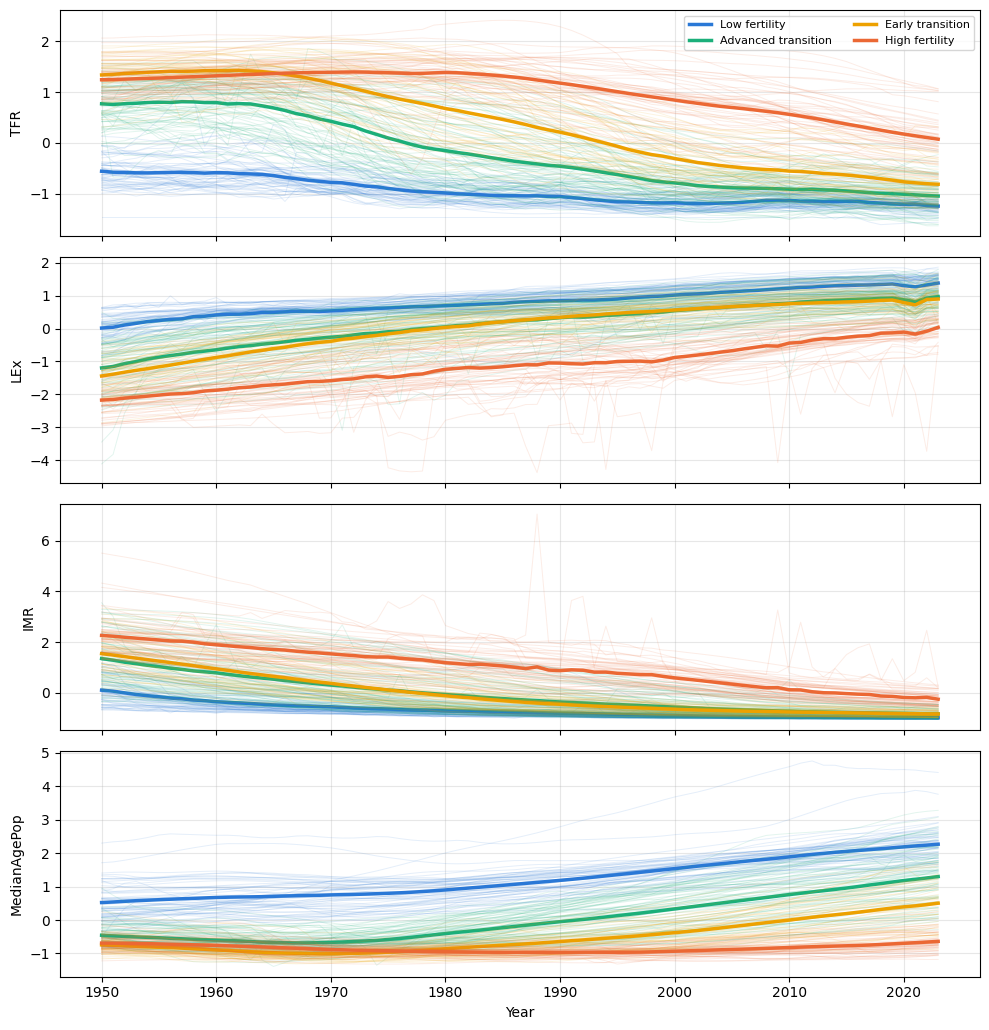

In [10]:
INDICADORES_PLOT = CONJUNTOS[CONJUNTO_FINAL]
anos = np.arange(PERIODO[0], PERIODO[1] + 1)

fig, eixos = plt.subplots(len(INDICADORES_PLOT), 1, figsize=(10, 2.6 * len(INDICADORES_PLOT)), sharex=True)
for i, ind in enumerate(INDICADORES_PLOT):
    ax = eixos[i]
    for g in range(K_FINAL):
        mascara = rot_consenso == g
        for serie in X_f[mascara]:
            ax.plot(anos, serie[:, i], color=CORES[g], alpha=0.12, linewidth=0.7)
        ax.plot(anos, X_f[mascara][:, :, i].mean(axis=0), color=CORES[g], linewidth=2.5,
                label=EN_GRUPO[nomes_grupos(K_FINAL)[g]])
    ax.set_ylabel(ind)
    ax.grid(alpha=0.3)
eixos[0].legend(loc="upper right", ncol=2, fontsize=8)
eixos[-1].set_xlabel("Year")
fig.tight_layout()
fig.savefig(PASTA_FIG / "04_trajectories_by_group.png", dpi=200, facecolor="white")
plt.show()

## 8. Mapa dos grupos

Cada país aparece com a cor do seu grupo no consenso. Os países com confiança abaixo de 0,6 aparecem esmaecidos: são casos de fronteira, que mudam de grupo conforme a semente.

In [11]:
dados_mapa = resultado[["LocID", "Location", "nome", "confianca"]].assign(nome=lambda d: d["nome"].map(EN_GRUPO))
escala_grupo = alt.Scale(domain=[EN_GRUPO[n] for n in nomes_grupos(K_FINAL)], range=CORES[:K_FINAL])

mapa_grupos = (
    alt.Chart(MALHA)
    .mark_geoshape(stroke="white", strokeWidth=0.3)
    .transform_filter("datum.id != 10")
    .transform_lookup(lookup="id", from_=alt.LookupData(dados_mapa, "LocID", ["nome", "Location", "confianca"]))
    .encode(
        opacity=alt.condition("datum.confianca < 0.6", alt.value(0.45), alt.value(1.0)),
        color=alt.condition(
            "isValid(datum.nome)",
            alt.Color("nome:N", scale=escala_grupo, legend=alt.Legend(title="Group")),
            alt.value("#d9d9d9"),
        ),
        tooltip=[alt.Tooltip("Location:N", title="Country"), alt.Tooltip("nome:N", title="Group")],
    )
    .project(type="equalEarth")
    .properties(width=680, height=340, title="Demographic transition groups (DTW consensus, 1950–2023)")
)
mapa_grupos

alt.Chart(...)

## 9. Grupos por época no mapa

Um único k-means é treinado com todas as épocas juntas, então cada grupo tem o mesmo significado em todas elas. Os grupos são numerados pela fecundidade média de cada época. Os nomes são os da seção 6.

In [12]:
EPOCAS = [1950, 1970, 1990, 2010, 2030, 2050, 2100]
INDICADORES_EPOCA = CONJUNTOS[CONJUNTO_FINAL]

def grupos_por_epoca(features, k, epocas=EPOCAS):
    # Um único k-means com todas as épocas: os grupos têm o mesmo significado em todas elas
    base = paises_medium[paises_medium["Time"].isin(epocas)].dropna(subset=features + ["TFR"]).copy()
    z = padronizar(base, features)
    modelo_pool = KMeans(n_clusters=k, n_init=20, random_state=42).fit(z[features])
    base["bruto"] = modelo_pool.labels_
    ordem = base.groupby("bruto")["TFR"].mean().sort_values().index
    rank = {g: i for i, g in enumerate(ordem)}
    return pd.DataFrame({
        "LocID": base["LocID"].values,
        "Location": base["Location"].values,
        "epoca": base["Time"].values,
        "grupo": base["bruto"].map(rank).values,
    })

grupos_epoca = grupos_por_epoca(INDICADORES_EPOCA, K_FINAL)
grupos_epoca["nome"] = grupos_epoca["grupo"].map(lambda g: nomes_grupos(K_FINAL)[g])
print(grupos_epoca.groupby(["epoca", "nome"]).size().unstack(fill_value=0)[nomes_grupos(K_FINAL)].to_string())

nome   Baixa fecundidade  Transição avançada  Transição inicial  Alta fecundidade
epoca                                                                            
1950                   0                  37                 62               138
1970                   1                  68                 94                74
1990                   5                 119                 83                30
2010                  58                 119                 57                 3
2030                 106                 101                 30                 0
2050                 138                  94                  5                 0
2100                 203                  34                  0                 0


In [13]:
def mapa_epoca(epoca, legenda=False):
    d = grupos_epoca[grupos_epoca["epoca"] == epoca][["LocID", "Location", "nome"]].assign(nome=lambda d: d["nome"].map(EN_GRUPO))
    return (
        alt.Chart(MALHA)
        .mark_geoshape(stroke="white", strokeWidth=0.2)
        .transform_filter("datum.id != 10")
        .transform_lookup(lookup="id", from_=alt.LookupData(d, "LocID", ["nome", "Location"]))
        .encode(
            color=alt.condition(
                "isValid(datum.nome)",
                alt.Color("nome:N", scale=escala_grupo, legend=None),
                alt.value("#d9d9d9"),
            ),
            tooltip=[alt.Tooltip("Location:N", title="Country"), alt.Tooltip("nome:N", title="Group")],
        )
        .project(type="equalEarth")
        .properties(width=400, height=200, title=str(epoca))
    )

legenda_grupos = (
    alt.Chart(pd.DataFrame({"nome": [EN_GRUPO[n] for n in nomes_grupos(K_FINAL)]}))
    .mark_square(size=220, filled=True)
    .encode(
        y=alt.Y("nome:N", sort=[EN_GRUPO[n] for n in nomes_grupos(K_FINAL)], axis=alt.Axis(title=None, orient="right")),
        color=alt.Color("nome:N", scale=escala_grupo, legend=None),
    )
    .properties(width=40, height=140, title="Group")
)

alt.hconcat(
    alt.vconcat(
        alt.hconcat(mapa_epoca(1950), mapa_epoca(1990)),
        alt.hconcat(mapa_epoca(2030), mapa_epoca(2100)),
    ),
    legenda_grupos,
)

alt.HConcatChart(...)

## 10. Hierárquica sobre DTW

Agrupamento hierárquico aglomerativo (ligação média) sobre a matriz de distâncias DTW. É determinístico, não depende de semente, e o dendrograma mostra a estrutura inteira dos grupos. Comparamos o corte em K grupos com o k-means e com o consenso.

In [14]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

D_f = cdist_dtw(X_f)
Z = linkage(squareform(D_f, checks=False), method="average")
rot_hier = ranquear(fcluster(Z, t=K_FINAL, criterion="maxclust") - 1, ids_f)

modelo_seed0 = TimeSeriesKMeans(n_clusters=K_FINAL, metric="dtw", random_state=0, n_init=5, max_iter=50, n_jobs=-1).fit(X_f)
rot_kmeans = ranquear(modelo_seed0.labels_, ids_f)

comparacao = pd.DataFrame([
    {"método": "k-means (semente 0)", "silhueta": silhouette_score(D_f, rot_kmeans, metric="precomputed"),
     "ARI vs consenso": adjusted_rand_score(rot_consenso, rot_kmeans)},
    {"método": "hierárquica (ligação média)", "silhueta": silhouette_score(D_f, rot_hier, metric="precomputed"),
     "ARI vs consenso": adjusted_rand_score(rot_consenso, rot_hier)},
    {"método": "consenso (10 sementes)", "silhueta": silhouette_score(D_f, rot_consenso, metric="precomputed"),
     "ARI vs consenso": 1.0},
]).round(3)
comparacao

,método,silhueta,ARI vs consenso
0,k-means (semente 0),0.272,0.767
1,hierárquica (ligação média),0.339,0.437
2,consenso (10 sementes),0.267,1.000


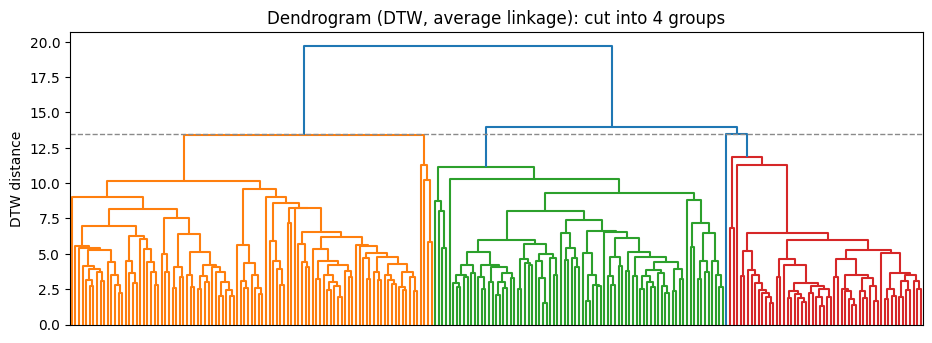

In [15]:
fig, ax = plt.subplots(figsize=(11, 3.8))
dendrogram(Z, no_labels=True, color_threshold=Z[-(K_FINAL - 1), 2], ax=ax)
ax.axhline(Z[-(K_FINAL - 1), 2], color="#8a8a8a", linestyle="--", linewidth=1)
ax.set_title(f"Dendrogram (DTW, average linkage): cut into {K_FINAL} groups")
ax.set_ylabel("DTW distance")
fig.savefig(PASTA_FIG / "04_dendrogram_dtw.png", dpi=200, facecolor="white")
plt.show()

**Leitura:** a hierárquica tem a maior silhueta (0,34, contra 0,27 do k-means e 0,27 do consenso), mas se afasta mais do consenso (ARI de 0,44, contra 0,77 do k-means). Ela separa melhor os grupos, sem produzir a mesma partição. A escolha entre os métodos é de interpretação: mantemos o consenso porque ele não depende de uma execução específica, e porque, ao contrário da hierárquica, mostra a confiança de cada país.

## 11. Validação com KNN

Um classificador KNN, treinado com os grupos do consenso, mede o quanto os grupos são separáveis: se a acurácia por validação cruzada é alta, os grupos são bem definidos. A matriz de confusão mostra quais grupos são confundidos entre si.

Usamos a própria distância DTW, com 5 vizinhos e validação cruzada estratificada em 5 partes.

In [16]:
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

prev_knn = np.empty(n_f, dtype=int)
for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(D_f, rot_consenso):
    knn = KNeighborsClassifier(n_neighbors=5, metric="precomputed").fit(D_f[np.ix_(tr, tr)], rot_consenso[tr])
    prev_knn[te] = knn.predict(D_f[np.ix_(te, tr)])

acuracia = (prev_knn == rot_consenso).mean()
print(f"Acurácia do KNN por validação cruzada: {acuracia:.3f}")

nomes_k = nomes_grupos(K_FINAL)
pd.crosstab(
    pd.Series([nomes_k[g] for g in rot_consenso], name="consenso"),
    pd.Series([nomes_k[g] for g in prev_knn], name="previsto pelo KNN"),
)

Acurácia do KNN por validação cruzada: 0.911


previsto pelo KNN,Alta fecundidade,Baixa fecundidade,Transição avançada,Transição inicial
consenso,,,,
Alta fecundidade,47,0,2,2
Baixa fecundidade,0,55,2,0
Transição avançada,0,2,67,8
Transição inicial,1,0,4,47


In [17]:
confundidos = pd.DataFrame({"país": nomes_f, "consenso": [nomes_k[g] for g in rot_consenso],
                            "previsto": [nomes_k[g] for g in prev_knn], "confiança": confianca})
confundidos = confundidos[prev_knn != rot_consenso].sort_values("confiança")
print(f"Países confundidos pelo KNN: {len(confundidos)}")
confundidos.head(15)

Países confundidos pelo KNN: 21


,país,consenso,previsto,confiança
136,Morocco,Transição avançada,Transição inicial,0.337662
206,Tajikistan,Transição inicial,Transição avançada,0.415385
58,El Salvador,Transição avançada,Transição inicial,0.438961
170,Qatar,Transição avançada,Transição inicial,0.457143
55,Dominica,Transição avançada,Transição inicial,0.481818
216,Turks and Caicos Islands,Transição avançada,Transição inicial,0.538961
212,United Arab Emirates,Transição avançada,Transição inicial,0.538961
140,Nauru,Transição inicial,Transição avançada,0.569231
98,Israel,Transição avançada,Baixa fecundidade,0.596104
190,Singapore,Transição avançada,Transição inicial,0.596104


## 12. KNN para atribuir grupos a países de fora

Para verificar a atribuição, treinamos o KNN com os países que passam no filtro de 1 milhão de habitantes (154 países) e atribuímos grupos aos 83 países menores. Comparamos essa atribuição com o consenso desses países, que foi calculado com todos os 237.

In [18]:
X_big, ids_big, _ = preparar(CONJUNTOS[CONJUNTO_FINAL], 1000)
modelo_big = TimeSeriesKMeans(n_clusters=K_FINAL, metric="dtw", random_state=0, n_init=5, max_iter=50, n_jobs=-1).fit(X_big)
rot_big = ranquear(modelo_big.labels_, ids_big)

mascara_pequenos = ~np.isin(ids_f, ids_big)
X_pequenos = X_f[mascara_pequenos]
ids_pequenos = np.array(ids_f)[mascara_pequenos]

knn_big = KNeighborsClassifier(n_neighbors=5, metric="precomputed").fit(cdist_dtw(X_big), rot_big)
atribuidos = knn_big.predict(cdist_dtw(X_pequenos, X_big))

concordancia = (atribuidos == rot_consenso[mascara_pequenos]).mean()
print(f"Países pequenos atribuídos: {len(ids_pequenos)} | concordância com o consenso: {concordancia:.3f}")
pd.Series([nomes_k[g] for g in atribuidos], name="grupo atribuído pelo KNN").value_counts()

Países pequenos atribuídos: 83 | concordância com o consenso: 0.530


grupo atribuído pelo KNN
Transição avançada    41
Baixa fecundidade     21
Transição inicial     11
Alta fecundidade      10
Name: count, dtype: int64

**Leitura da validação (11):** com DTW e 5 vizinhos, a acurácia por validação cruzada é de 0,91. Os 21 países confundidos estão em fases vizinhas: 8 países de transição avançada são classificados como transição inicial, e 4 de transição inicial como transição avançada.

**Leitura da atribuição (12):** para os 83 países pequenos, o KNN reproduz o consenso em apenas 53% dos casos. A validação mostra que o KNN separa bem os grupos quando todos os países estão no treino; com o treino restrito aos 154 países grandes, a atribuição perde precisão. Por isso a atribuição é uma estimativa exploratória, não um resultado para a apresentação.

## 13. Salvar o consenso

Salvamos o consenso em um arquivo separado, `clusters_dtw_consenso.csv`, com a confiança de cada país. O arquivo `clusters_dtw.csv`, lido pelo dashboard, não muda.

In [19]:
consenso.to_csv(RAIZ / "data" / "processed" / "clusters_dtw_consenso.csv", index=False)
print("Salvo: clusters_dtw_consenso.csv")

Salvo: clusters_dtw_consenso.csv


## 14. Conjunto C: treino completo com consenso

O conjunto C reúne as 11 variáveis selecionadas pelo VIF no notebook 01. Ele não substitui o A por padrão: aqui treinamos o C com o mesmo protocolo do A (10 sementes, consenso e confiança) e comparamos os dois nos países em comum.

O conjunto C não tem TFR nem LEx; no lugar delas, usa NRR e LE60, que são quase equivalentes (ver o VIF). A Santa Sé fica de fora porque não tem LE60 no suplemento.

In [20]:
X_c, ids_c, nomes_c = preparar(CONJUNTOS["C: 11 variáveis (VIF)"], None)
n_c = len(ids_c)
print(f"Conjunto C: {n_c} países, {X_c.shape[1]} anos, {X_c.shape[2]} indicadores")

rot_execucoes_c = np.array([
    TimeSeriesKMeans(n_clusters=K_FINAL, metric="dtw", random_state=s, n_init=5, max_iter=50, n_jobs=-1).fit(X_c).labels_
    for s in SEMENTES_CONSENSO
])

coassoc_c = np.zeros((n_c, n_c))
for r in rot_execucoes_c:
    coassoc_c += (r[:, None] == r[None, :])
coassoc_c /= len(rot_execucoes_c)

rot_consenso_c = ranquear(
    AgglomerativeClustering(n_clusters=K_FINAL, metric="precomputed", linkage="average").fit_predict(1 - coassoc_c),
    ids_c,
)
confianca_c = np.array([coassoc_c[i, rot_consenso_c == rot_consenso_c[i]].mean() for i in range(n_c)])
D_c = cdist_dtw(X_c)

# Comparação com o conjunto A, nos países presentes nos dois
comuns = sorted(set(ids_c) & set(ids_f))
pos_c = [list(ids_c).index(i) for i in comuns]
pos_f = [list(ids_f).index(i) for i in comuns]
ari_A_C = adjusted_rand_score(rot_consenso[pos_f], rot_consenso_c[pos_c])

def resumo_conjunto(nome, D, rot_cons, rot_exec, conf, n):
    pares = [adjusted_rand_score(a, b) for i, a in enumerate(rot_exec) for b in rot_exec[i + 1:]]
    return {
        "conjunto": nome,
        "countries": n,
        "silhueta do consenso": round(silhouette_score(D, rot_cons, metric="precomputed"), 3),
        "ARI médio entre sementes": round(np.mean(pares), 3),
        "ARI médio execução × consenso": round(np.mean([adjusted_rand_score(rot_cons, r) for r in rot_exec]), 3),
        "confiança média": round(conf.mean(), 3),
        "países com confiança < 0,6": int((conf < 0.6).sum()),
    }

comparacao_ac = pd.DataFrame([
    resumo_conjunto("A (4 indicadores)", D_f, rot_consenso, rotulos_execucoes, confianca, n_f),
    resumo_conjunto("C (11 variáveis VIF)", D_c, rot_consenso_c, rot_execucoes_c, confianca_c, n_c),
])
print(f"ARI entre o consenso A e o consenso C, nos {len(comuns)} países em comum: {ari_A_C:.3f}")
comparacao_ac

Conjunto C: 236 países, 74 anos, 11 indicadores


ARI entre o consenso A e o consenso C, nos 236 países em comum: 0.274


,conjunto,countries,silhueta do consenso,ARI médio entre sementes,ARI médio execução × consenso,confiança média,"países com confiança < 0,6"
0,A (4 indicadores),237,0.267,0.599,0.646,0.762,54
1,C (11 variáveis VIF),236,0.165,0.641,0.701,0.771,51


In [21]:
distribuicao_c = (
    pd.DataFrame({"Location": nomes_c, "nome": [nomes_k[g] for g in rot_consenso_c], "confiança": confianca_c})
)
print(distribuicao_c.groupby("nome")["confiança"].agg(["size", "mean"]).round(3))

consenso_c = pd.DataFrame({
    "LocID": ids_c, "Location": nomes_c, "grupo": rot_consenso_c,
    "nome": [nomes_k[g] for g in rot_consenso_c], "confianca": confianca_c.round(3),
})
consenso_c.to_csv(RAIZ / "data" / "processed" / "clusters_dtw_conjunto_c.csv", index=False)
print("Salvo: clusters_dtw_conjunto_c.csv")

                    size   mean
nome                           
Alta fecundidade      77  0.879
Baixa fecundidade     49  0.969
Transição avançada    82  0.584
Transição inicial     28  0.674
Salvo: clusters_dtw_conjunto_c.csv


**Leitura:** o conjunto C não é uma melhoria clara sobre o A. A estabilidade é parecida (ARI médio entre cada execução e o consenso de 0,70, contra 0,65 do A), a confiança média também (0,77 contra 0,76), e o número de países incertos é semelhante (51 contra 54). Os grupos do C são menos separados: a silhueta do consenso é 0,17, contra 0,27 do A. Os dois consensos concordam pouco (ARI de 0,27 nos 236 países em comum): com outras variáveis, os países se agrupam de outra forma. Por isso mantemos o A como resultado principal, e o C mostra que a partição depende do conjunto de indicadores.

## 15. Sankey: migração entre grupos por época

Cada coluna é uma época; cada bloco é um grupo, com o número de países no tamanho do bloco. Os fluxos ligam os países que estavam em um grupo numa época e estão em outro na época seguinte. A cor do fluxo é a do grupo de origem.

In [22]:
def hex_para_rgba(cor, alfa):
    r, g, b = (int(cor[i:i + 2], 16) for i in (1, 3, 5))
    return f"rgba({r},{g},{b},{alfa})"

def sankey_epocas(grupos, k):
    nomes = [EN_GRUPO[n] for n in nomes_grupos(k)]
    epocas = sorted(grupos["epoca"].unique())
    total = grupos["LocID"].nunique()
    contagem = grupos.groupby(["epoca", "grupo"]).size()

    # Posições fixas: uma coluna por época; blocos empilhados do topo para a base
    margem_topo, altura_util, espaco = 0.90, 0.80, 0.02
    x_pos, y_pos, rotulos, cores_no, no_idx = [], [], [], [], {}
    for i, epoca in enumerate(epocas):
        x = 0.02 + i * (0.96 / (len(epocas) - 1))
        y = margem_topo
        for g in range(k):
            n = int(contagem.get((epoca, g), 0))
            if n == 0:
                continue
            altura = altura_util * n / total
            no_idx[(epoca, g)] = len(rotulos)
            x_pos.append(x)
            y_pos.append(min(0.99, max(0.01, y - altura / 2)))
            rotulos.append(f"{n}")
            cores_no.append(CORES[g])
            y -= altura + espaco

    origem, destino, valor, cor_fluxo, texto = [], [], [], [], []
    for e1, e2 in zip(epocas[:-1], epocas[1:]):
        a = grupos[grupos["epoca"] == e1].set_index("LocID")["grupo"]
        b = grupos[grupos["epoca"] == e2].set_index("LocID")["grupo"]
        juntos = pd.concat([a.rename("de"), b.rename("para")], axis=1).dropna()
        for (de, para), n in juntos.groupby(["de", "para"]).size().items():
            origem.append(no_idx[(e1, int(de))])
            destino.append(no_idx[(e2, int(para))])
            valor.append(int(n))
            cor_fluxo.append(hex_para_rgba(CORES[int(de)], 0.45))
            texto.append(f"{n} países: {nomes[int(de)]} em {e1} → {nomes[int(para)]} em {e2}")

    fig = go.Figure(go.Sankey(
        arrangement="fixed",
        node=dict(label=rotulos, x=x_pos, y=y_pos, color=cores_no, pad=4, thickness=18,
                  line=dict(color="white", width=0.5)),
        link=dict(source=origem, target=destino, value=valor, color=cor_fluxo,
                  customdata=texto, hovertemplate="%{customdata}<extra></extra>"),
    ))

    anotacoes = [
        dict(x=0.02 + i * (0.96 / (len(epocas) - 1)), y=1.06, xref="paper", yref="paper",
             text=f"<b>{epoca}</b>", showarrow=False, font=dict(size=13))
        for i, epoca in enumerate(epocas)
    ]
    legenda = "   ".join(f"<span style='color:{CORES[g]}'>■</span> {nomes[g]}" for g in range(k))
    anotacoes.append(dict(x=0.5, y=-0.04, xref="paper", yref="paper", text=legenda,
                          showarrow=False, font=dict(size=12)))

    fig.update_layout(
        title=dict(text="Countries by group in each period (number of countries per block)", x=0.01),
        height=560, margin=dict(l=20, r=20, t=90, b=80),
        annotations=anotacoes, font=dict(family="Arial", size=12),
        paper_bgcolor="white", plot_bgcolor="white",
    )
    return fig

fig_sankey = sankey_epocas(grupos_epoca, K_FINAL)
fig_sankey

## 16. Salvar resultados

- `data/processed/clusters_dtw.csv`: grupo de cada país, com o nome (usado pelo dashboard).
- `data/processed/clusters_dtw_consenso.csv`: consenso entre 10 sementes, com a confiança de cada país (seção 13).
- `data/processed/grupos_por_epoca.csv`: grupo de cada país em cada época.
- `figures/sankey_grupos_por_epoca.html`: Sankey interativo, para a apresentação.

In [23]:
SAIDA_CLUSTERS = RAIZ / "data" / "processed" / "clusters_dtw.csv"
SAIDA_EPOCAS = RAIZ / "data" / "processed" / "grupos_por_epoca.csv"
SAIDA_SANKEY = RAIZ / "figures" / "sankey_grupos_por_epoca.html"

SAIDA_CLUSTERS.parent.mkdir(parents=True, exist_ok=True)
SAIDA_SANKEY.parent.mkdir(parents=True, exist_ok=True)

resultado[["LocID", "Location", "grupo", "nome", "confianca"]].to_csv(SAIDA_CLUSTERS, index=False)
grupos_epoca[["LocID", "Location", "epoca", "grupo", "nome"]].to_csv(SAIDA_EPOCAS, index=False)
fig_sankey.write_html(str(SAIDA_SANKEY))
fig_sankey.write_image(str(PASTA_FIG / "04_sankey_groups_by_period.png"), scale=2)
print("Salvos:", SAIDA_CLUSTERS.name, SAIDA_EPOCAS.name, SAIDA_SANKEY.name)

Salvos: clusters_dtw.csv grupos_por_epoca.csv sankey_grupos_por_epoca.html


## Limitações

- **Número de grupos:** para o conjunto A sem filtro, K = 3 tem a melhor silhueta e a melhor estabilidade. A escolha de K = 4 é de interpretação (seção 4), e os resultados de K = 3 devem ser mencionados ao lado.
- **DTW sensível à semente:** o ARI entre sementes mostra quanto o resultado depende da inicialização. O resultado final usa o consenso entre 10 sementes (seção 5), mas a instabilidade existe: 54 países têm confiança abaixo de 0,6.
- **Clusterização por época** usa um único k-means com todas as épocas. Assim, os grupos têm o mesmo significado no tempo, mas a posição de cada país é avaliada em cada época isoladamente: um país pode mudar de grupo por causa da posição relativa dos outros, não só da própria trajetória.
- **Projeções:** os grupos e o Sankey de 2030 em diante usam projeções, não observações.